# 3. Chain dynamics, imposed phase patterns, and gauge tests

**Question:** how does an initially localized doublon spread in a specified
finite-chain Hamiltonian? Source: thesis Sec. 3.8.2; `heff2_spacetime.py`.

**Important distinction:** the original script calls one uniform-bond pattern
`drive` and asserts arbitrary-angle realization. The thesis conclusion limits
the analysed physical scheme to angles $0,\pi$. Here that pattern is named
**legacy_drive (assumed)**. Its mathematical equivalence can be tested; the
physical implementation claim remains unresolved. A diagonal gauge identity
alone does not prove that site-resolved laser controls generate the assumed
identical bond phases. We do not label generic-angle plots as a realized drive.

## Conventions, dimensions, and evidence status

**Theoretical model:** each site has the orthonormal occupation basis
$|0\rangle,|1\rangle,|2\rangle$. The tensor-product basis is lexicographic,
with the leftmost site the most significant index. Occupations above two are
excluded. State vectors have norm one; probabilities and occupation numbers
are dimensionless. Chains use open boundaries unless explicitly stated.
This is a nonrelativistic finite-dimensional calculation; no spacetime metric
signature is used. Finite sums replace spatial integration, and no continuum
boundary conditions are assumed.

Start with physical energy $H$ and positive reference angular frequency
$\omega_{\rm ref}$. Define
$$K=\frac{H}{\hbar\omega_{\rm ref}},\qquad
  \tau=\omega_{\rm ref}t,\qquad \hbar=\frac{h}{2\pi}.$$
Since $[H]={\rm J}$ and $[\hbar\omega_{\rm ref}]={\rm J\,s}\,{\rm s}^{-1}
={\rm J}$, $K$ is dimensionless. Likewise $[\tau]={\rm s}^{-1}{\rm s}=1$.
Schrödinger evolution becomes
$$i\hbar\,\omega_{\rm ref}\frac{d\psi}{d\tau}
   =\hbar\omega_{\rm ref}K\psi,
  \qquad i\frac{d\psi}{d\tau}=K\psi.$$

**Unresolved source convention:** archived scripts label numerical rates as
MHz while using the numerical matrix in $\exp(-iEt)$; a header also equates MHz with rad/us.
Appendix B of the thesis writes $\omega'/2\pi$ in MHz. If a matrix is supplied
as $H/h$ in cycles per unit time, its propagator is $\exp[-i2\pi(H/h)t]$;
if supplied as $H/\hbar$, it is $\exp[-i(H/\hbar)t]$. Dimensional analysis
cannot distinguish these two conventions. The notebooks therefore preserve
native numerical values and use $\tau$, without claiming a calibrated
microsecond axis. Any physical conversion requires a declared convention.
For the effective-model numerical cells, the reference is one native rate
unit: a rate divided by that reference has the same numerical value.
Thus the arrays used in the propagator are dimensionless $K$, even when
the source-formula coefficients are described below as native rates.

**Source-backed numerical facts** refer to the archived files and checks
shown here. They are not experimental observations. **Physical reachability**
and **proposed extensions** are labelled separately. See
[scientific notes](../SCIENTIFIC_NOTES.md) for unresolved interpretations.

## 3.1 Density in a fixed sector

A doublon means two occupation quanta on one site, not two additional sites.
Choose the Fock state with $n_{j_0}=2$ and all other occupations zero.
Its total number is $N=2$. Number conservation keeps evolution in this sector.

For basis configuration $s$, its occupation at site $j$ is the known integer
$n_j(s)$. Since the number operator is diagonal,
$$\langle n_j(\tau)\rangle
  =\sum_{s,s'}\psi_s^*(\tau)\langle s|n_j|s'\rangle\psi_{s'}(\tau)
  =\sum_s|\psi_s(\tau)|^2 n_j(s).$$
Summing sites and using $\sum_j n_j(s)=N$ gives
$$\sum_j\langle n_j(\tau)\rangle
  =\sum_s|\psi_s(\tau)|^2 N=N.$$
Density is dimensionless and lies between zero and two in the truncated model.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
from dataclasses import replace
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

here = Path.cwd().resolve()
roots = [p for p in (here, *here.parents) if (p / 'anyon_thesis').is_dir()]
if not roots:
    raise FileNotFoundError('Open this notebook from the cloned repository.')
ROOT = roots[0]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from anyon_thesis.models import (
    EffectiveParameters, effective_bond, effective_chain, occupation_basis,
    phase_pattern, basis_state, evolve_probabilities, parameter_curves,
    target_hamiltonian, lowest_levels, gap_grid,
)
SAVE_FIGURES = False  # Optional export; raw scripts/data are never overwritten.
STYLE = {'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False}
def show_figure(fig, name):
    if SAVE_FIGURES:
        destination = ROOT / 'notebook_outputs'
        destination.mkdir(exist_ok=True)
        fig.savefig(destination / f'{name}.png', dpi=160)
    display(fig)
    plt.close(fig)
np.set_printoptions(precision=6, suppress=True)

In [2]:
diagonal, rates, _ = effective_bond()
L, N, origin = 8, 2, 3
initial = np.zeros(L, dtype=int)
initial[origin] = 2
tau = np.linspace(0, 250, 251)
angles = [0.0, np.pi/2, np.pi]
densities = []
for angle in angles:
    H, basis = effective_chain(L, diagonal, rates, phase_pattern('target', angle), N)
    P = evolve_probabilities(H, basis_state(basis, initial), tau)
    densities.append(P @ basis)
assert all(np.allclose(d.sum(axis=1), N, atol=1e-11) for d in densities)
print('L=', L, 'N=', N, 'sector dimension=', len(basis))
print('Initial density:', densities[0][0])

L= 8 N= 2 sector dimension= 36
Initial density: [0. 0. 0. 2. 0. 0. 0. 0.]


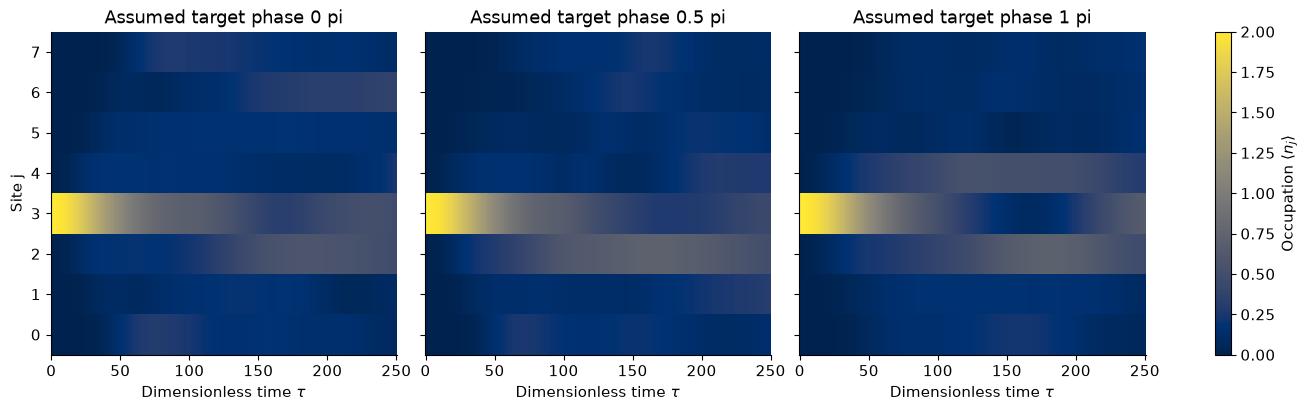

Maximum deviations of total density from N: [2.6645352591003757e-15, 2.6645352591003757e-15, 3.1086244689504383e-15]


In [3]:
with plt.rc_context(STYLE):
    fig, axes = plt.subplots(1, 3, figsize=(13, 4), layout='constrained', sharey=True)
    for ax, angle, density in zip(axes, angles, densities):
        mesh = ax.pcolormesh(tau, np.arange(L), density.T,
                             shading='nearest', cmap='cividis', vmin=0, vmax=2)
        ax.set(xlabel=r'Dimensionless time $\tau$', title=f'Assumed target phase {angle/np.pi:g} pi')
    axes[0].set_ylabel('Site j')
    fig.colorbar(mesh, ax=axes, label=r'Occupation $\langle n_j\rangle$')
    show_figure(fig, '03_chain_density')
print('Maximum deviations of total density from N:',
      [float(np.max(abs(d.sum(axis=1)-N))) for d in densities])

**Figure description:** each panel shows site occupation versus time for the
same initial doublon and a different assumed phase. All panels share limits
$0\leq\langle n_j\rangle\leq2$ and use nearest-cell rendering without
smoothing. The conservation errors are printed above. These are finite-chain
model predictions, not experimental data or proof of physical reachability.

## 3.2 Work through the gauge identity

In the channel order $01\to10$, $11\to20$, $02\to11$, $12\to21$, define
$$\boldsymbol\vartheta_{\rm legacy}(\theta)=(0,\theta,-2\theta,-\theta),
  \qquad \boldsymbol\vartheta_{\rm target}(\phi)=(0,\phi,0,\phi).$$
Let $D(s)$ count sites with occupation two, and define a diagonal unitary
$Q|s\rangle=e^{i2\theta D(s)}|s\rangle$. Each matrix element transforms as
$$(Q^\dagger KQ)_{s's}
   =e^{-i2\theta D(s')}K_{s's}e^{i2\theta D(s)}.$$
The occupation changes in the four channels give changes in $D$ of
$0,+1,-1,0$. Hence the four transformed phases are
$$0-0=0,\quad \theta-2\theta=-\theta,\quad
  -2\theta+2\theta=0,\quad -\theta-0=-\theta.$$
They match the target pattern at $\phi=-\theta$. The bond diagonals do not
change. This proves an identity **between the two assigned Hamiltonians**.
It does not prove the complete target AHM unless the four magnitudes and
diagonal terms also match, or prove the assigned laser control is realizable.

Because $Q$ is diagonal, $|\langle s|Q\psi\rangle|^2=|\psi_s|^2$.
For an initial occupation state, the overall initial phase is unobservable,
so occupation densities agree under this mapping.

In [4]:
theta = 0.73
legacy, cfg = effective_chain(L, diagonal, rates, phase_pattern('legacy_drive', theta), N)
assumed_target, _ = effective_chain(L, diagonal, rates, phase_pattern('target', -theta), N)
phase = np.exp(2j*theta*np.sum(cfg == 2, axis=1))
transformed = phase.conj()[:, None]*legacy*phase[None, :]
discrepancy = np.max(abs(transformed-assumed_target))
assert discrepancy < 1e-12
print('Gauge identity for the assigned matrices:', discrepancy)
print('Physical realization: not established by this test.')

Gauge identity for the assigned matrices: 1.11023408142925e-16
Physical realization: not established by this test.


## 3.3 Limiting cases and time reversal

Integer occupations imply $e^{i(\phi+2\pi)n}=e^{i\phi n}$; density dynamics
therefore repeats under $\phi\to\phi+2\pi$. At zero hopping the initial
occupation stays fixed. The reference initial state is real, and the
assigned model satisfies $K(-\phi)=K(\phi)^*$. Thus
$$\psi(\tau;-\phi)=e^{-iK(\phi)^*\tau}\psi_0
  =[e^{+iK(\phi)\tau}\psi_0]^*=\psi(-\tau;\phi)^*.$$
Taking absolute squares gives $n_j(\tau;-\phi)=n_j(-\tau;\phi)$.
It does not, without an additional symmetry, give
$n_j(\tau;-\phi)=n_j(\tau;\phi)$.

In [5]:
def density_at(angle, times, hopping=rates):
    K, cfg = effective_chain(L, diagonal, hopping, phase_pattern('target', angle), N)
    return evolve_probabilities(K, basis_state(cfg, initial), times) @ cfg
periodic_error = np.max(abs(density_at(0, tau)-density_at(2*np.pi, tau)))
reversal_error = np.max(abs(density_at(-0.7, tau)-density_at(0.7, -tau)))
frozen = density_at(0.7, tau, np.zeros(4))
assert periodic_error < 1e-11
assert reversal_error < 1e-11
assert np.allclose(frozen, np.tile(initial, (len(tau), 1)))
print('2 pi periodicity error:', periodic_error)
print('Time-reversal identity error:', reversal_error)
print('Zero-hopping occupation limit: PASS')

2 pi periodicity error: 1.3322676295501878e-15
Time-reversal identity error: 0.0
Zero-hopping occupation limit: PASS


## Sources and limits of this notebook

- Aditya Banerjee, *Linear Anyon Model with Rydberg Atoms*, Universitat de
  Barcelona, 2026: [institutional record](https://hdl.handle.net/2445/231684).
  See the relevant sections and equations identified above.
- [Archived thesis and code deposit](https://doi.org/10.5281/zenodo.23443035).
- Original scripts in [`scripts/`](../scripts/) at source commit
  `22959963191fcbc4d283ec4b272b506ad6dd979b`; this notebook is a new explanatory
  implementation. The original script and data bytes are preserved.
- [SciPy `eigsh` documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.sparse.linalg.eigsh.html)
  for the sparse eigenvalue solver. For complex Hermitian input, SciPy uses
  its complex eigensolver internally; residual checks remain necessary.

These finite-size calculations do not independently validate the microscopic
derivation, establish an experimental realization, or prove a thermodynamic
phase transition. No new empirical evidence is introduced.